# 06 · Native track: sensing and estimation

> **In short:** the native controller never sees MuJoCo truth. Seeded sensors produce noisy measurements, a 12D error-state EKF estimates the vehicle and one Kalman filter per obstacle estimates its motion. This notebook runs one headless episode and compares truth, measurement and estimate.
>
> **Runtime:** about 30 s (MuJoCo + do-mpc) · **Read alongside:** [Sensing and estimation](../2.Code/docs/concepts/estimation.md) · [Native simulation](../2.Code/docs/guides/native-simulation.md)

**You will:**

- run a native episode from Python with `run_headless_episode`
- check the vehicle estimate against its 3σ covariance band
- see the obstacle tracker smooth noisy position measurements

In [1]:
from nbsetup import *

In [2]:
from quadrotor_mpc.application.native.headless import run_headless_episode
from quadrotor_mpc.application.native.telemetry import load_native_recording

SCENARIO = CONFIG / "mujoco_native_ccmpc.yaml"


def run(mode, seed=1001, duration=None):
    episode = run_headless_episode(SCENARIO, mode=mode, seed=seed, duration_s=duration, base_dir=OUTPUT)
    print(f"{mode:13s} {episode.result['termination_reason']}, collision={episode.result['collided']}, "
          f"recording: {episode.recording.name}")
    return load_native_recording(episode.recording)


def column(recording, name):
    return np.array([float(row[name]) if row[name] not in ("", None) else np.nan for row in recording["rows"]])

In [3]:
recording = run("joint_uniform", duration=3.0 if FAST else 6.0)
time_s = column(recording, "time_s")
truth = recording["states"]
estimate = recording["estimated_states"]
covariance = recording["error_covariances"]
measured = recording["vehicle_measurements"]
print("ticks:", len(time_s), "| state", truth.shape, "| error covariance", covariance.shape)

joint_uniform duration_reached, collision=False, recording: 20261011T145921Z_ccmpc-mujoco-native-estimated-dynamic-joint_uniform
ticks: 120 | state (120, 13) | error covariance (120, 12, 12)


## Vehicle position: estimate vs truth

The shaded band is ±3σ from the EKF covariance. A consistent filter keeps the error inside it almost
all the time; dots are the raw position measurements.

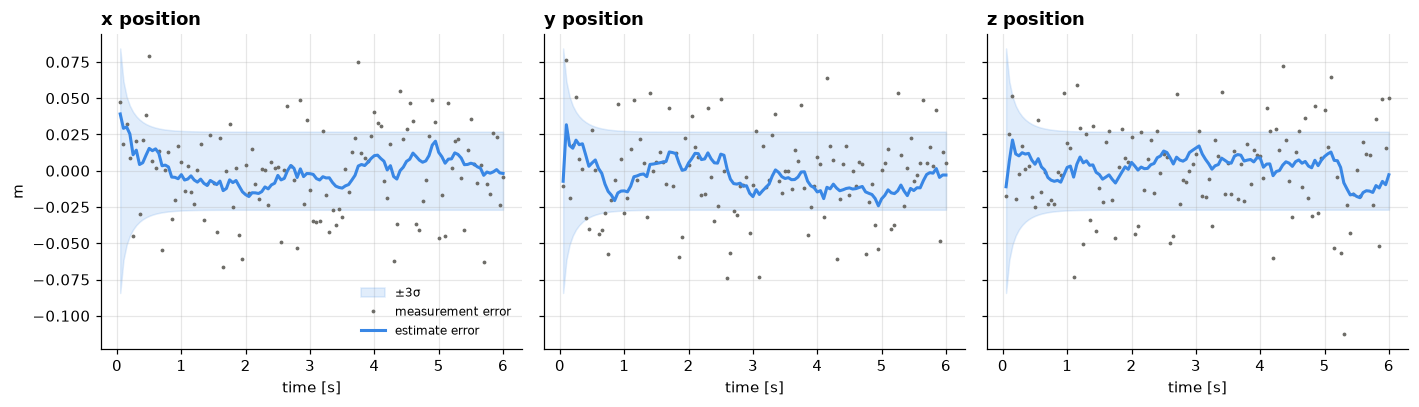

RMSE estimate 0.0102 m vs measurement 0.0305 m
mean position NEES 3.20 (3 for a perfectly consistent filter); inside ±3σ: 100.0%


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for axis, (ax, name) in enumerate(zip(axes, "xyz")):
    error = estimate[:, axis] - truth[:, axis]
    sigma = np.sqrt(covariance[:, axis, axis])
    ax.fill_between(time_s, -3 * sigma, 3 * sigma, color=CONTROLLER_COLORS["deterministic"], alpha=0.15, label="±3σ")
    ax.plot(time_s, measured[:, axis] - truth[:, axis], ".", ms=3, color=NEUTRAL, label="measurement error")
    ax.plot(time_s, error, color=CONTROLLER_COLORS["deterministic"], lw=2, label="estimate error")
    ax.set(title=f"{name} position", xlabel="time [s]")
axes[0].set_ylabel("m")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

position_error = estimate[:, :3] - truth[:, :3]
nees = np.array([e @ np.linalg.solve(P[:3, :3], e) for e, P in zip(position_error, covariance)])
inside = np.mean(np.abs(position_error) <= 3 * np.sqrt(np.diagonal(covariance[:, :3, :3], axis1=1, axis2=2)))
print(f"RMSE estimate {np.sqrt(np.mean(position_error**2)):.4f} m vs measurement "
      f"{np.sqrt(np.mean((measured[:, :3] - truth[:, :3])**2)):.4f} m")
print(f"mean position NEES {nees.mean():.2f} (3 for a perfectly consistent filter); inside ±3σ: {inside:.1%}")

## Obstacle tracking

Only obstacle **positions** are measured; velocity is inferred by the constant-velocity filter. The
controller uses the tracker's prediction, never the configured truth motion.

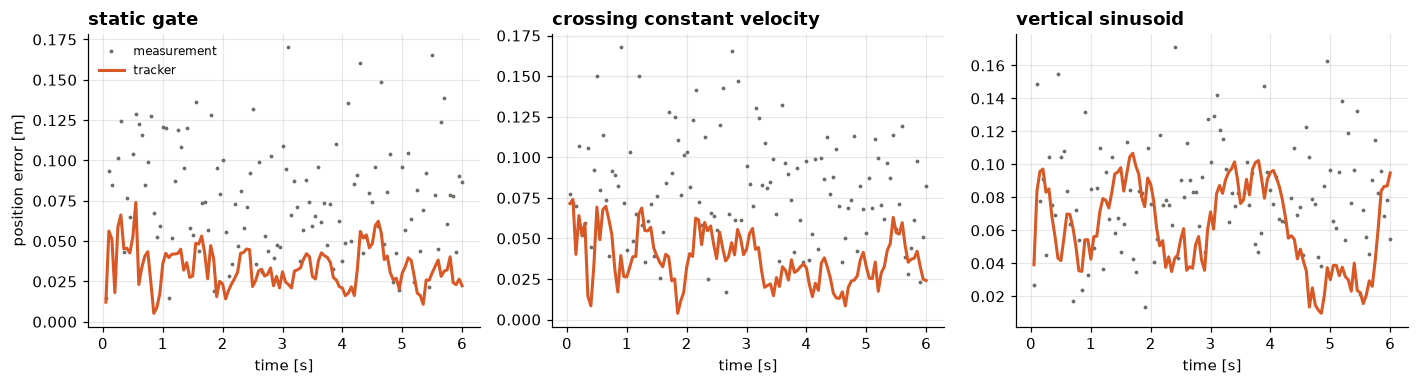

In [5]:
truth_obstacles = recording["obstacle_predictions"][:, :, 0, :]
tracked = recording["estimated_obstacle_predictions"][:, :, 0, :]
measured_obstacles = recording["obstacle_measurements"]
names = [item["name"] for item in recording["scenario"]["obstacles"]]

fig, axes = plt.subplots(1, len(names), figsize=(13, 3.6))
for j, (ax, name) in enumerate(zip(axes, names)):
    ax.plot(time_s, np.linalg.norm(measured_obstacles[:, j] - truth_obstacles[:, j], axis=1), ".", ms=3,
            color=NEUTRAL, label="measurement")
    ax.plot(time_s, np.linalg.norm(tracked[:, j] - truth_obstacles[:, j], axis=1), lw=2,
            color=CONTROLLER_COLORS["individual"], label="tracker")
    ax.set(title=name.replace("_", " "), xlabel="time [s]")
axes[0].set_ylabel("position error [m]")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Takeaways

- The estimate is noticeably better than a single measurement, and its covariance is a usable
  statement of uncertainty; that covariance is what the next notebook propagates and turns into margins.
- `estimation.enabled: false` (configs `mujoco_native.yaml`, `mujoco_native_dynamic.yaml`) feeds exact
  truth instead and is the deterministic regression baseline.

---

**Previous:** [05_ode_controller_comparison.ipynb](05_ode_controller_comparison.ipynb) · **Next:** [07_native_uncertainty_and_risk.ipynb](07_native_uncertainty_and_risk.ipynb)